# 13. One model trained on all five datasets

Notebooks 04–10 train on the main dataset only, and notebooks 11–12 use the external data
only to *test* those models or to train a separate binary detector. Here a single 16-label
model is trained on the main dataset **and** the external data together, and compared with
the main-only model on the same held-out arguments.

**What goes into training** (`src/external.py: combined_dataset`):

| source | rows used for training | split |
|---|---|---|
| main | all arguments | official 80/10/10 split |
| edu (LOGIC) | arguments with ≥ 1 of our 16 labels | hash of near-duplicate cluster, 70/15/15 |
| comments (CoCoLoFa + Touché) | "No Fallacy" comments as **all-zero rows** (valid arguments), fallacious comments with ≥ 1 of our labels | the split of notebook 12, unchanged |
| contrastive pairs | none: the file gives no fallacy *type*, so a fallacious twin has no 16-label target, and training on the valid twins alone would teach "this writing style = valid". Both twins are used for evaluation only | the split of notebook 12 |

Fallacious rows whose only labels are outside our 16 are dropped: as all-zero rows they would
wrongly be taught as valid. With the valid comments included, the model can now predict
**no fallacy at all**, which the main-only model never saw in training.

**Protocol (declared before modelling).** TF-IDF uni+bigrams fitted on the combined **train**
rows only; linear SVM (the best main-data family), C ∈ {0.1, 0.3, 1, 3} × class weight
{none, balanced}, chosen by macro-F1 on the pooled **validation** rows of the trainable sources
(ties → smaller C). The selected configuration is refitted on train and scored **once** on each
test split. The main-only reference is the configuration of `results/selection.json`
(`LinearSVM`), refitted on the main train split, exactly as in notebook 10.

**Test-set use.** This is a further use of the main test split, after notebook 10. Nothing in
notebooks 01–12 was changed by it, and nothing here is chosen on test.

**Disclosure.** The first execution printed one edu argument in two splits (two copies that
differ only in an apostrophe, which the near-duplicate grouping did not join). Its grouping was
fixed to use punctuation-free text and the notebook was run again; the results of the first
run are not reported. The fix was decided from the leakage check in the first cell, not from
the test scores, and the model-selection rule above was not changed.

In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import f1_score, accuracy_score
from src.config import RESULTS, FIGURES, SEED
from src.data import load_dataset
from src.features import word_tfidf
from src.models import linear_svm
from src.evaluate import bootstrap_ci
from src.external import combined_dataset

_, LABELS = load_dataset()
sel = json.loads((RESULTS / "selection.json").read_text())
cw = lambda s: None if s in (None, "None") else "balanced"
D = combined_dataset(LABELS)
norm = D.argument.str.lower().str.replace(r"[^a-z0-9 ]", "", regex=True).str.strip()
cross = D.assign(k=norm).groupby("k").split.nunique()
print("identical texts in more than one split:", int((cross > 1).sum()))
pd.crosstab([D.source, D.trainable], D.split, margins=True)

identical texts in more than one split: 0


,split,test,train,val,All
source,trainable,,,,
cocolofa,True,31,124,27,182
contrastive,False,186,974,246,1406
edu,True,314,1482,298,2094
main,True,1757,14341,1768,17866
touche,True,125,522,104,751
All,,2413,17443,2443,22299


## 13.1 Model selection on validation

In [2]:
TR = D[D.trainable & (D.split == "train")]; VA = D[D.trainable & (D.split == "val")]
vec = word_tfidf(ngram_range=(1, 2)); A_tr = vec.fit_transform(TR.argument); A_va = vec.transform(VA.argument)
Y_tr, Y_va = TR[LABELS].values, VA[LABELS].values
rows = []
for c in [0.1, 0.3, 1.0, 3.0]:
    for w in [None, "balanced"]:
        P = linear_svm(c, w).fit(A_tr, Y_tr).predict(A_va)
        r = {"C": c, "class_weight": str(w), "val_macro_f1": f1_score(Y_va, P, average="macro", zero_division=0)}
        for s in ["main", "edu", "cocolofa", "touche"]:
            m = (VA.source == s).values; fal = m & (VA.is_fallacy == 1).values
            pres = Y_va[fal].sum(0) > 0
            r[f"val_macro_f1 {s}"] = f1_score(Y_va[fal][:, pres], P[fal][:, pres], average="macro", zero_division=0)
        v = (VA.is_fallacy == 0).values
        r["val valid kept clean"] = float((P[v].sum(1) == 0).mean())
        rows.append(r)
grid = pd.DataFrame(rows); grid.to_csv(RESULTS / "combined_val_grid.csv", index=False)
best = grid.sort_values(["val_macro_f1", "C"], ascending=[False, True]).iloc[0]
sel["combined"] = {"model": "TF-IDF uni+bi LinearSVM on main + edu + comments", "C": float(best.C),
                   "class_weight": best.class_weight, "val_macro_f1": float(best.val_macro_f1),
                   "selected_by": "pooled validation macro-F1 (notebook 13), before any test split was scored"}
(RESULTS / "selection.json").write_text(json.dumps(sel, indent=2, default=float))
print("selected:", sel["combined"])
grid.round(3)

selected: {'model': 'TF-IDF uni+bi LinearSVM on main + edu + comments', 'C': 1.0, 'class_weight': 'balanced', 'val_macro_f1': 0.772022251143982, 'selected_by': 'pooled validation macro-F1 (notebook 13), before any test split was scored'}


,C,class_weight,val_macro_f1,val_macro_f1 main,val_macro_f1 edu,val_macro_f1 cocolofa,val_macro_f1 touche,val valid kept clean
0,0.1,None,0.495,0.536,0.172,0.000,0.036,0.987
1,0.1,balanced,0.743,0.793,0.440,0.225,0.261,0.590
2,0.3,None,0.618,0.659,0.313,0.000,0.094,0.923
3,0.3,balanced,0.763,0.816,0.453,0.296,0.383,0.679
4,1.0,None,0.727,0.785,0.391,0.125,0.266,0.833
5,1.0,balanced,0.772,0.823,0.471,0.271,0.301,0.744
6,3.0,None,0.764,0.817,0.430,0.271,0.306,0.821
7,3.0,balanced,0.766,0.814,0.464,0.271,0.301,0.769


"val valid kept clean" is the share of valid validation comments for which the model predicts
no fallacy (higher is better; the main-only model cannot do this by construction).

## 13.2 Final test evaluation (run once)
Both models are scored on the same test arguments. For the multi-label scores, macro-F1 is
taken over the labels each source annotates (as in notebook 11). For fallacy vs. valid,
"fallacy" means at least one label is predicted, and pairs are ranked by the highest SVM margin.

In [3]:
s = sel["combined"]
comb = linear_svm(s["C"], cw(s["class_weight"])).fit(A_tr, Y_tr)
m0 = sel["LinearSVM"]
MAIN_TR = D[(D.source == "main") & (D.split == "train")]
vec0 = word_tfidf(ngram_range=(1, 2)); A0 = vec0.fit_transform(MAIN_TR.argument)
main_only = linear_svm(m0["C"], cw(m0["class_weight"])).fit(A0, MAIN_TR[LABELS].values)
MODELS = {"main data only": (main_only, vec0), "all datasets": (comb, vec)}
TE = D[D.split == "test"].reset_index(drop=True)
pred = {k: m.predict(v.transform(TE.argument)) for k, (m, v) in MODELS.items()}
marg = {k: m.decision_function(v.transform(TE.argument)).max(1) for k, (m, v) in MODELS.items()}

rows = []
for name, mask in [("main test", (TE.source == "main").values),
                   ("edu test", (TE.source == "edu").values),
                   ("comments test (fallacious)", TE.source.isin(["cocolofa", "touche"]).values & (TE.is_fallacy == 1).values)]:
    Y = TE[LABELS].values[mask]; pres = Y.sum(0) > 0; Y = Y[:, pres]
    Pa, Pb = pred["main data only"][mask][:, pres], pred["all datasets"][mask][:, pres]
    for k, P in [("main data only", Pa), ("all datasets", Pb)]:
        lo, hi = bootstrap_ci(Y, P, "macro_f1", n_boot=1000, seed=SEED)
        r = {"test set": name, "model": k, "n": int(mask.sum()), "labels scored": int(pres.sum()),
             "macro_f1": f1_score(Y, P, average="macro", zero_division=0), "macro_f1_95ci": f"[{lo:.3f}, {hi:.3f}]",
             "micro_f1": f1_score(Y, P, average="micro", zero_division=0)}
        if k == "all datasets":
            dlo, dhi = bootstrap_ci(Y, Pb, "macro_f1", n_boot=1000, seed=SEED, y_pred_b=Pa)
            r["delta_vs_main_only_95ci"] = f"[{dlo:+.3f}, {dhi:+.3f}]"
        rows.append(r)
multi = pd.DataFrame(rows); multi.round(3)

,test set,model,n,labels scored,macro_f1,macro_f1_95ci,micro_f1,delta_vs_main_only_95ci
0,main test,main data only,1757,16,0.805,"[0.760, 0.831]",0.832,NaN
1,main test,all datasets,1757,16,0.803,"[0.758, 0.830]",0.829,"[-0.007, +0.005]"
2,edu test,main data only,314,13,0.323,"[0.250, 0.377]",0.375,NaN
3,edu test,all datasets,314,13,0.445,"[0.355, 0.503]",0.508,"[+0.074, +0.165]"
4,comments test (fallacious),main data only,68,5,0.319,"[0.195, 0.433]",0.340,NaN
5,comments test (fallacious),all datasets,68,5,0.297,"[0.154, 0.407]",0.299,"[-0.133, +0.078]"


In [4]:
rng = np.random.default_rng(SEED)
def acc_ci(y, p, n=1000):
    v = [accuracy_score(y[i], p[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return np.percentile(v, [2.5, 97.5])

brows = []
for name, mask in [("comments test", TE.source.isin(["cocolofa", "touche"]).values),
                   ("contrastive test", (TE.source == "contrastive").values)]:
    y = TE.is_fallacy.values[mask]
    for k in MODELS:
        f = (pred[k][mask].sum(1) > 0).astype(int); lo, hi = acc_ci(y, f)
        brows.append({"test set": name, "model": k, "n": int(mask.sum()), "accuracy": accuracy_score(y, f),
                      "accuracy_95ci": f"[{lo:.3f}, {hi:.3f}]", "majority accuracy": max(y.mean(), 1 - y.mean()),
                      "valid flagged as fallacy (FPR)": f[y == 0].mean(), "fallacies flagged (recall)": f[y == 1].mean()})
binary = pd.DataFrame(brows)
K = TE[TE.source == "contrastive"]
pair_rank = {}
for k in MODELS:
    t = K.assign(s=marg[k][K.index]).pivot_table(index="pair", columns="is_fallacy", values="s", aggfunc="first").dropna()
    pair_rank[k] = float((t[1] > t[0]).mean())
print("contrastive test pairs where the fallacious twin gets the higher margin:", {k: round(v, 3) for k, v in pair_rank.items()}, "of", len(t))
binary.round(3)

contrastive test pairs where the fallacious twin gets the higher margin: {'main data only': 0.634, 'all datasets': 0.677} of 93


,test set,model,n,accuracy,accuracy_95ci,majority accuracy,valid flagged as fallacy (FPR),fallacies flagged (recall)
0,comments test,main data only,156,0.513,"[0.436, 0.590]",0.564,0.523,0.559
1,comments test,all datasets,156,0.538,"[0.455, 0.622]",0.564,0.307,0.338
2,contrastive test,main data only,186,0.602,"[0.532, 0.672]",0.500,0.462,0.667
3,contrastive test,all datasets,186,0.613,"[0.538, 0.688]",0.500,0.452,0.677


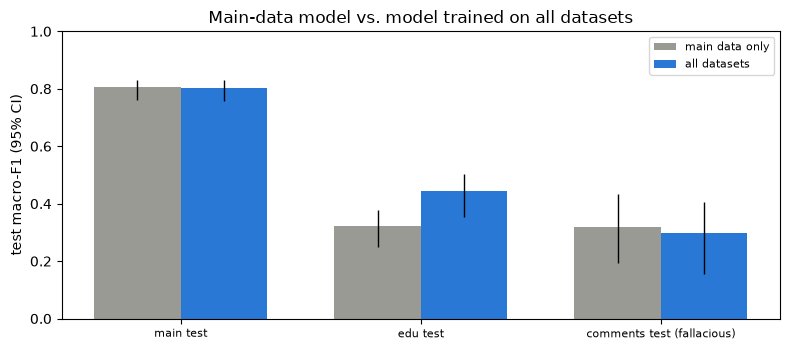

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
sets = list(multi["test set"].unique()); w = 0.36
for i, k in enumerate(MODELS):
    g = multi[multi.model == k].set_index("test set").loc[sets]
    lo = [float(x.strip("[]").split(",")[0]) for x in g.macro_f1_95ci]; hi = [float(x.strip("[]").split(",")[1]) for x in g.macro_f1_95ci]
    x = np.arange(len(sets)) + (i - 0.5) * w
    ax.bar(x, g.macro_f1, w, label=k, color=["#9a9a95", "#2a78d6"][i])
    ax.errorbar(x, g.macro_f1, yerr=[g.macro_f1 - lo, np.array(hi) - g.macro_f1], fmt="none", c="k", lw=1)
ax.set_xticks(np.arange(len(sets))); ax.set_xticklabels(sets, fontsize=8); ax.set_ylim(0, 1)
ax.set_ylabel("test macro-F1 (95% CI)"); ax.legend(fontsize=8); ax.set_title("Main-data model vs. model trained on all datasets")
plt.tight_layout(); plt.savefig(FIGURES / "combined_vs_main.png", dpi=150); plt.show()

## 13.3 Per-label F1 on the main test split
Does adding external data help or hurt individual fallacies of the main task?

In [6]:
mm = (TE.source == "main").values
pl = pd.DataFrame({"main test n": TE[LABELS].values[mm].sum(0),
                   "F1 main data only": f1_score(TE[LABELS].values[mm], pred["main data only"][mm], average=None, zero_division=0),
                   "F1 all datasets": f1_score(TE[LABELS].values[mm], pred["all datasets"][mm], average=None, zero_division=0)}, index=LABELS)
pl["change"] = pl["F1 all datasets"] - pl["F1 main data only"]
pl.sort_values("change").round(3)

,main test n,F1 main data only,F1 all datasets,change
Equivocation,86,0.873,0.855,-0.018
False Dilemma,146,0.840,0.827,-0.013
Straw Man,35,0.800,0.787,-0.013
Appeal to Emotion,208,0.844,0.832,-0.012
False Cause / Causality,215,0.819,0.810,-0.009
Circular Reasoning,74,0.820,0.811,-0.009
Appeal to Authority,316,0.860,0.854,-0.006
Hasty Generalization,207,0.714,0.710,-0.004
Bandwagon / Popularity,281,0.802,0.799,-0.003
Affirming the Consequent,15,0.800,0.800,0.000


## 13.4 Reading the results
* **Main task: no change.** On the main test split the combined model scores 0.803 macro-F1
  against 0.805 for the main-only model; the paired 95% interval of the difference,
  [−0.007, +0.005], contains zero. The extra 2,128 training rows neither help nor hurt it.
* **LOGIC (edu): a clear gain.** 0.445 against 0.323 macro-F1, paired interval
  [+0.074, +0.165]. Seeing edu-style training text helps on edu-style test text, but the score
  stays far below the main test split.
* **Online comments: no measurable gain** in naming the fallacy (0.297 vs 0.319, interval
  [−0.133, +0.078], only 68 test comments), and it is **still not a usable fallacy-vs-valid
  detector**: 0.538 accuracy against 0.564 for always answering the majority class. Training
  on valid comments makes it flag fewer valid comments (31% instead of 52%) but also miss more
  fallacies (recall 34% instead of 56%): it learned to say "no fallacy" more often, not to tell
  the two apart.
* **Contrastive pairs (never trained on):** 0.613 vs 0.602 accuracy, and the fallacious twin
  gets the higher score in 68% of 93 pairs (63% before): within noise of each other.

More data from other sources helps a bag-of-words model only on text that resembles those
sources. It does not make it reason about argument structure, which is the main finding of
notebooks 06–12 again.


## 13.5 The website's inspector model: Lasso on all datasets
The interactive inspector runs a Lasso logistic regression in the browser (its weights are
sparse enough to ship). It is retrained here on the same combined training rows, so it can also
answer "no fallacy". Declared before fitting: class weighting stays `balanced` (the main-data
Lasso's choice), C ∈ {10, 100, 1000} is chosen by pooled validation macro-F1 (ties → smaller C),
and the test splits are scored once. `src/export_web.py` rebuilds exactly this model.

In [7]:
from src.models import logreg
lrows = []
for c in [10.0, 100.0, 1000.0]:
    P = logreg("l1", c, "balanced").fit(A_tr, Y_tr).predict(A_va)
    v = (VA.is_fallacy == 0).values
    lrows.append({"C": c, "val_macro_f1": f1_score(Y_va, P, average="macro", zero_division=0),
                  "val valid kept clean": float((P[v].sum(1) == 0).mean())})
lgrid = pd.DataFrame(lrows)
lbest = lgrid.sort_values(["val_macro_f1", "C"], ascending=[False, True]).iloc[0]
sel["combined_lasso"] = {"model": "TF-IDF uni+bi LR-L1 on main + edu + comments (website inspector)", "C": float(lbest.C),
                         "class_weight": "balanced", "val_macro_f1": float(lbest.val_macro_f1),
                         "selected_by": "pooled validation macro-F1 (notebook 13), before any test split was scored"}
(RESULTS / "selection.json").write_text(json.dumps(sel, indent=2, default=float))
print("selected:", sel["combined_lasso"]); lgrid.round(3)

selected: {'model': 'TF-IDF uni+bi LR-L1 on main + edu + comments (website inspector)', 'C': 1000.0, 'class_weight': 'balanced', 'val_macro_f1': 0.74320538207347, 'selected_by': 'pooled validation macro-F1 (notebook 13), before any test split was scored'}


,C,val_macro_f1,val valid kept clean
0,10.0,0.737,0.500
1,100.0,0.742,0.603
2,1000.0,0.743,0.718


In [8]:
las = logreg("l1", sel["combined_lasso"]["C"], "balanced").fit(A_tr, Y_tr)
PL = las.predict(vec.transform(TE.argument))
lasso_test = []
for name, mask in [("main test", (TE.source == "main").values), ("edu test", (TE.source == "edu").values),
                   ("comments test (fallacious)", TE.source.isin(["cocolofa", "touche"]).values & (TE.is_fallacy == 1).values)]:
    Y = TE[LABELS].values[mask]; pres = Y.sum(0) > 0
    lo, hi = bootstrap_ci(Y[:, pres], PL[mask][:, pres], "macro_f1", n_boot=1000, seed=SEED)
    lasso_test.append({"test set": name, "macro_f1": f1_score(Y[:, pres], PL[mask][:, pres], average="macro", zero_division=0),
                       "macro_f1_95ci": f"[{lo:.3f}, {hi:.3f}]"})
for name, mask in [("comments test", TE.source.isin(["cocolofa", "touche"]).values), ("contrastive test", (TE.source == "contrastive").values)]:
    y = TE.is_fallacy.values[mask]; f = (PL[mask].sum(1) > 0).astype(int)
    lasso_test.append({"test set": name + " (fallacy vs valid)", "accuracy": accuracy_score(y, f),
                       "valid flagged as fallacy (FPR)": f[y == 0].mean(), "fallacies flagged (recall)": f[y == 1].mean()})
lasso_test = pd.DataFrame(lasso_test); lasso_test.round(3)

,test set,macro_f1,macro_f1_95ci,accuracy,valid flagged as fallacy (FPR),fallacies flagged (recall)
0,main test,0.776,"[0.728, 0.805]",NaN,NaN,NaN
1,edu test,0.424,"[0.349, 0.482]",NaN,NaN,NaN
2,comments test (fallacious),0.293,"[0.155, 0.405]",NaN,NaN,NaN
3,comments test (fallacy vs valid),NaN,NaN,0.571,0.307,0.412
4,contrastive test (fallacy vs valid),NaN,NaN,0.570,0.559,0.699


The inspector model behaves like the combined SVM: close to the main-data models on the main
test split, and on the comments it says "no fallacy" more often for valid and fallacious
comments alike. On the website it is a tool for exploring what drives a prediction, not a
validated fallacy-vs-valid detector.

In [9]:
summary = {"counts": D.groupby(["source", "split"]).size().rename("n").reset_index().to_dict("records"),
           "val_grid": grid.to_dict("records"), "selected": sel["combined"],
           "multi": multi.replace({np.nan: None}).to_dict("records"), "binary": binary.to_dict("records"),
           "pair_rank": pair_rank, "n_test_pairs": int(len(t)),
           "per_label_main": pl.reset_index(names="label").to_dict("records"),
           "n_train": int(len(TR)), "n_train_by_source": TR.source.value_counts().to_dict(),
           "lasso": {"val_grid": lgrid.to_dict("records"), "selected": sel["combined_lasso"], "test": lasso_test.replace({np.nan: None}).to_dict("records")}}
(RESULTS / "combined_summary.json").write_text(json.dumps(summary, indent=2, default=float))
for r in summary["multi"]: print(r)
for r in summary["binary"]: print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in r.items()})

{'test set': 'main test', 'model': 'main data only', 'n': 1757, 'labels scored': 16, 'macro_f1': 0.8045460250513587, 'macro_f1_95ci': '[0.760, 0.831]', 'micro_f1': 0.8320545609548167, 'delta_vs_main_only_95ci': None}
{'test set': 'main test', 'model': 'all datasets', 'n': 1757, 'labels scored': 16, 'macro_f1': 0.8026390155208198, 'macro_f1_95ci': '[0.758, 0.830]', 'micro_f1': 0.8290066509332761, 'delta_vs_main_only_95ci': '[-0.007, +0.005]'}
{'test set': 'edu test', 'model': 'main data only', 'n': 314, 'labels scored': 13, 'macro_f1': 0.3229220456404611, 'macro_f1_95ci': '[0.250, 0.377]', 'micro_f1': 0.37453183520599254, 'delta_vs_main_only_95ci': None}
{'test set': 'edu test', 'model': 'all datasets', 'n': 314, 'labels scored': 13, 'macro_f1': 0.44522544358088123, 'macro_f1_95ci': '[0.355, 0.503]', 'micro_f1': 0.5078740157480315, 'delta_vs_main_only_95ci': '[+0.074, +0.165]'}
{'test set': 'comments test (fallacious)', 'model': 'main data only', 'n': 68, 'labels scored': 5, 'macro_f1':